In [1]:
%%HTML
<style>
    body {
        --vscode-font-family: "Roboto Thin"
    }
</style>

<center>
<h1> SuGaR: Surface-Aligned Gaussian Splatting for Efficient 3D Mesh Reconstruction 
    <br>and High-Quality Mesh Rendering</h1>
Antoine Guédon and Vincent Lepetit

In [49]:
import sys
import os

# Add the directory containing your module to the Python path
module_path = '/export/mkrishn9/new_sugar/SuGaR'
if module_path not in sys.path:
    sys.path.append(module_path)

sys.path.append('/export/mkrishn9/new_sugar/SuGaR/gaussian_splatting')

In [50]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import open3d as o3d
from pytorch3d.io import load_objs_as_meshes
from pytorch3d.renderer import (
    AmbientLights,
    RasterizationSettings, 
    MeshRenderer, 
    MeshRasterizer,  
    SoftPhongShader,
    )
from pytorch3d.renderer.blending import BlendParams
from sugar_scene.gs_model import GaussianSplattingWrapper
from sugar_scene.sugar_model import SuGaR, load_refined_model
from sugar_utils.spherical_harmonics import SH2RGB

In [51]:
numGPU = 4
torch.cuda.set_device(numGPU)

# Load data and vanilla Gaussian Splatting

In [52]:
# ========== Loading parameters ==========
use_eval_split = False
n_skip_images_for_eval_split = 8

iteration_to_load = 7000
# iteration_to_load = 30_000

load_gt_images = False
use_custom_bbox = False

Choose a data directory (the directory that contains the images subdirectory).

In [10]:
# Example
source_path = '/export/mkrishn9/SuGaR/tandt/truck/'
#source_path = '/export/mkrishn9/SuGaR/tandt/train/'



In [ ]:
source_path = '/export/mkrishn9/SuGaR/db/drjohnson/'

In [53]:
source_path = '/export/mkrishn9/SuGaR/mipnerf/garden'

Choose a corresponding vanilla Gaussian Splatting checkpoint directory.

In [11]:
# Example
gs_checkpoint_path = '/export/mkrishn9/SuGaR/truck_gs_chkpt/'
#

In [8]:
gs_checkpoint_path = '/export/mkrishn9/SuGaR/drjohnson_gs_chkpt/'

In [11]:
gs_checkpoint_path = '/export/mkrishn9/SuGaR/bicycle_gs_chkpt/'

Load data and 3DGS checkpoint.

In [54]:
# ====================Load NeRF model and training data====================

# Load Gaussian Splatting checkpoint 
print(f"\nLoading config {gs_checkpoint_path}...")
if use_eval_split:
    print("Performing train/eval split...")
nerfmodel = GaussianSplattingWrapper(
    source_path=source_path,
    output_path=gs_checkpoint_path,
    iteration_to_load=iteration_to_load,
    load_gt_images=load_gt_images,
    eval_split=use_eval_split,
    eval_split_interval=n_skip_images_for_eval_split,
    )

print(f'{len(nerfmodel.training_cameras)} training images detected.')
print(f'The model has been trained for {iteration_to_load} steps.')
print(len(nerfmodel.gaussians._xyz) / 1e6, "M gaussians detected.")


Loading config /export/mkrishn9/SuGaR/bicycle_gs_chkpt/...
Found image extension .JPG
194 training images detected.
The model has been trained for 7000 steps.
3.490494 M gaussians detected.


# Render with a refined SuGaR model

Choose a corresponding refined SuGaR checkpoint directory (located in `refined/<your scene>`)

In [13]:
# Example 
refined_sugar_folder = "/export/mkrishn9/new_sugar/SuGaR/truck/output_truck_1/refined/truck/sugarfine_3Dgs7000_sdfestim02_sdfnorm01_level03_decim1000000_normalconsistency01_gaussperface1"

In [ ]:
refined_sugar_folder = "/export/mkrishn9/new_sugar/SuGaR/db/output_drj_pic/refined/drjohnson/sugarfine_3Dgs7000_sdfestim02_sdfnorm02_level03_decim1000000_normalconsistency01_gaussperface1"

In [10]:
refined_sugar_folder = "/export/mkrishn9/new_sugar/SuGaR/output_mipnerf_better_mesh/refined/kitchen/sugarfine_3Dgs7000_sdfestim02_sdfnorm01_level03_decim1000000_normalconsistency01_gaussperface1"

In [55]:
refined_sugar_folder = "/export/mkrishn9/new_sugar/SuGaR/mipnerf/output_mipnerf_0_nokitchen/refined/garden/sugarfine_3Dgs7000_sdfestim02_sdfnorm01_level03_decim1000000_normalconsistency01_gaussperface1"

In [63]:
refined_sugar_folder = "/export/mkrishn9/new_sugar/SuGaR/db/output_4/refined/playroom/sugarfine_3Dgs7000_sdfestim02_sdfnorm01_level03_decim1000000_normalconsistency01_gaussperface1"

Choose a refinement iteration to load.

In [56]:
refined_iteration_to_load = 15_000

Load the refined SuGaR checkpoint.

In [64]:
refined_sugar_path = os.path.join(refined_sugar_folder, f"{refined_iteration_to_load}.pt")
print(f"\nLoading config {refined_sugar_path}...")

refined_sugar = load_refined_model(refined_sugar_path, nerfmodel)


Loading config /export/mkrishn9/new_sugar/SuGaR/db/output_4/refined/playroom/sugarfine_3Dgs7000_sdfestim02_sdfnorm01_level03_decim1000000_normalconsistency01_gaussperface1/15000.pt...
Loading refined model...
987437 faces detected.
987437 gaussians detected.
1 gaussians per surface triangle detected.
Binding radiance cloud to surface mesh...


Render an image.

Rendering image with index 182.
Image name: _DSC8862


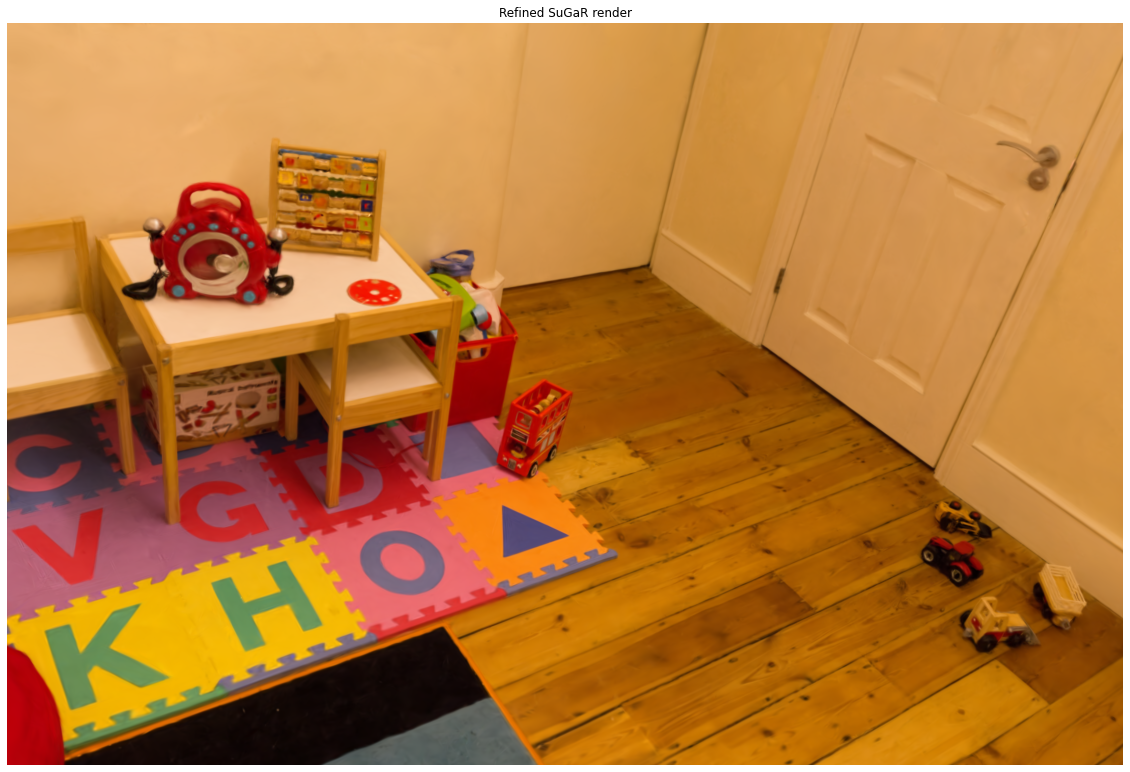

In [ ]:
onsamerow = True
also_render_vanilla_3dgs = False

# -----Camera to render-----
cameras_to_use = nerfmodel.training_cameras
# cameras_to_use = nerfmodel.test_cameras

cam_idx = np.random.randint(0, len(cameras_to_use.gs_cameras))
# --------------------------
#cam_idx = 237
refined_sugar.eval()
refined_sugar.adapt_to_cameras(cameras_to_use)

print(f"Rendering image with index {cam_idx}.")
print("Image name:", cameras_to_use.gs_cameras[cam_idx].image_name)

verbose = False
normalize_img = False

if load_gt_images:
    gt_rgb = nerfmodel.get_gt_image(cam_idx)
    i_sugar = 2
else:
    i_sugar = 1

with torch.no_grad():
    if also_render_vanilla_3dgs:
        gs_image = nerfmodel.render_image(
            nerf_cameras=cameras_to_use,
            camera_indices=cam_idx).clamp(min=0, max=1)
    
    sugar_image = refined_sugar.render_image_gaussian_rasterizer(
        nerf_cameras=cameras_to_use, 
        camera_indices=cam_idx,
        # bg_color=1. * torch.Tensor([1.0, 1.0, 1.0]).to(rc_fine.device),
        sh_deg=nerfmodel.gaussians.active_sh_degree,
        compute_color_in_rasterizer=True,
    ).nan_to_num().clamp(min=0, max=1)

# Change this to adjust the size of the plot
plot_ratio = 2. # 0.7, 1.5, 5
save_path = "/export/mkrishn9/new_sugar/SuGaR/figures/garden.png"

if also_render_vanilla_3dgs:
    plt.figure(figsize=(10 * plot_ratio, 10 * plot_ratio))
    plt.axis("off")
    plt.title("Vanilla 3DGS render")
    plt.imshow(gs_image.cpu().numpy())
    plt.show()
plt.figure(figsize=(10 * plot_ratio, 10 * plot_ratio))
plt.axis("off")
#plt.title("Refined SuGaR render")

plt.imshow(sugar_image.cpu().numpy())
#plt.savefig(save_path, bbox_inches='tight', pad_inches=0, dpi=300)  #truck: 56,155,40
plt.show()

torch.cuda.empty_cache()

# Render with a traditional color texture for SuGaR mesh

Select the path to the textured mesh (i.e. the obj file in `refined_mesh/<your scene>`).<br>
If None, the path to the mesh will be automatically computed from the checkpoint path.

In [36]:
#refined_mesh_path = "/export/mkrishn9/new_sugar/SuGaR/db/output_2/refined_mesh/drjohnson/sugarfine_3Dgs7000_sdfestim02_sdfnorm02_level03_decim1000000_normalconsistency01_gaussperface1.obj"
refined_mesh_path = "/export/mkrishn9/new_sugar/SuGaR/db/output_drj_pic/refined_mesh/drjohnson/sugarfine_3Dgs7000_sdfestim02_sdfnorm02_level03_decim1000000_normalconsistency01_gaussperface1.obj"

In [124]:
refined_mesh_path = "/export/mkrishn9/new_sugar/SuGaR/output_mipnerf_better_mesh/refined_mesh/stump/sugarfine_3Dgs7000_sdfestim02_sdfnorm01_level03_decim1000000_normalconsistency01_gaussperface1.obj"

In [25]:
refined_mesh_path = "/export/mkrishn9/new_sugar/SuGaR/mipnerf/output_mipnerf_0_nokitchen/refined_mesh/bicycle/sugarfine_3Dgs7000_sdfestim02_sdfnorm01_level03_decim1000000_normalconsistency01_gaussperface1.obj"

Load mesh.

In [16]:
if refined_mesh_path is None:
    post_processed = False

    if post_processed:
        post_processed_str = '_postprocessed'
    else:
        post_processed_str = ''

    scene_name = refined_sugar_path.split('/')[-3]
    refined_mesh_dir = './output/refined_mesh'
    refined_mesh_path = os.path.join(
        refined_mesh_dir, scene_name,
        refined_sugar_path.split('/')[-2].split('.')[0] + '.obj'
    )
    
print(f"Loading refined mesh from {refined_mesh_path}, this could take a minute...")
textured_mesh = load_objs_as_meshes([refined_mesh_path]).to(nerfmodel.device)
print(f"Loaded textured mesh with {len(textured_mesh.verts_list()[0])} vertices and {len(textured_mesh.faces_list()[0])} faces.")

Loading refined mesh from /export/mkrishn9/new_sugar/SuGaR/mipnerf/output_mipnerf_0_nokitchen/refined_mesh/bicycle/sugarfine_3Dgs7000_sdfestim02_sdfnorm01_level03_decim1000000_normalconsistency01_gaussperface1.obj, this could take a minute...
Loaded textured mesh with 696826 vertices and 1376680 faces.


In [47]:
from pytorch3d.renderer import Materials, HardPhongShader,SoftSilhouetteShader
from pytorch3d.io import load_ply
from pytorch3d.structures import Meshes
from pytorch3d.renderer.mesh.textures import Textures

# Load your PLY file
ply_mesh_path = "/export/mkrishn9/new_sugar/SuGaR/output_vanilla_mipnerf/coarse_mesh/bicycle/sugarmesh_vanilla3dgs_level03_decim1000000.ply"
vertices, faces = load_ply(ply_mesh_path)
mesh = Meshes(verts=[vertices], faces=[faces]).to(refined_sugar.device)
faces_per_pixel = 1
max_faces_per_bin = 50_000
cam_idx = 34

mesh_raster_settings = RasterizationSettings(
    image_size=(refined_sugar.image_height, refined_sugar.image_width),
    blur_radius=0.0, 
    faces_per_pixel=faces_per_pixel,
    # max_faces_per_bin=max_faces_per_bin
)
rasterizer = MeshRasterizer(
            cameras=cameras_to_use.p3d_cameras[cam_idx], 
            raster_settings=mesh_raster_settings,
        )
lights = AmbientLights(device=nerfmodel.device)
renderer = MeshRenderer(
        rasterizer=rasterizer,
        shader=SoftSilhouetteShader()
    )

mesh.textures = torch.ones_like(vertices)[None]


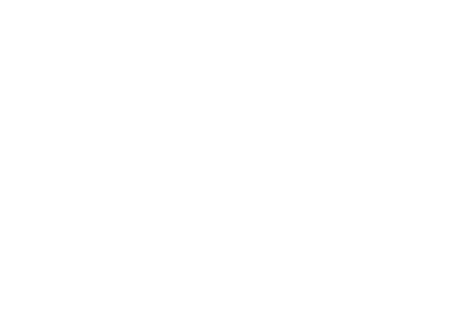

In [48]:
with torch.no_grad():
    rendered_img = renderer(mesh)[0, ..., :3].cpu().numpy()

plt.figure(figsize=(8, 8))
plt.axis("off")
plt.imshow(rendered_img)
plt.show()

In [ ]:
# -----Camera index to render-----
#cam_idx = np.random.randint(0, len(cameras_to_use))
# --------------------------
for i in range(1):
    cam_idx = 34
    faces_per_pixel = 1
    max_faces_per_bin = 50_000
    
    mesh_raster_settings = RasterizationSettings(
        image_size=(refined_sugar.image_height, refined_sugar.image_width),
        blur_radius=0.0, 
        faces_per_pixel=faces_per_pixel,
        # max_faces_per_bin=max_faces_per_bin
    )
    lights = AmbientLights(device=nerfmodel.device)
    #materials = Materials(device=refined_sugar.device, ambient_color=((1, 1, 1),))
    rasterizer = MeshRasterizer(
            cameras=cameras_to_use.p3d_cameras[cam_idx], 
            raster_settings=mesh_raster_settings,
        )
    renderer = MeshRenderer(
        rasterizer=rasterizer,
        shader=SoftPhongShader(
            device=refined_sugar.device, 
            cameras=cameras_to_use.p3d_cameras[cam_idx],
            lights=lights,
            #materials = materials,
            # blend_params=BlendParams(background_color=(0.0, 0.0, 0.0)),
            blend_params=BlendParams(background_color=(1.0, 1.0, 1.0)),
        )
    )
    save_path = "/export/mkrishn9/new_sugar/SuGaR/figures/mesh_bicycle.png"
    with torch.no_grad():    
        print("Rendering image", cam_idx)
        print("Image ID:", cameras_to_use.gs_cameras[cam_idx].image_name)
        
        p3d_cameras = cameras_to_use.p3d_cameras[cam_idx]
        rgb_img = renderer(textured_mesh, cameras=p3d_cameras)[0, ..., :3]
        grayscale_img = rgb_img.mean(dim=-1, keepdim=True).repeat(1, 1, 3)
    # Change this to adjust the size of the plot
    plot_ratio = 2.
    
    plt.figure(figsize=(10 * plot_ratio, 10 * plot_ratio))
    plt.axis("off")
    #plt.title("Refined SuGaR mesh with a traditional color UV texture")
    plt.imshow(rgb_img.cpu().numpy())
    plt.savefig(save_path, bbox_inches='tight', pad_inches=0, dpi=300)
    plt.show()

TypeError: __init__() missing 1 required positional argument: 'shader'

In [104]:
import os
import open3d as o3d

# Load the mesh as you already have

# Convert the mesh to Open3D format
vertices = textured_mesh.verts_list()[0].cpu().numpy()  # Convert vertices to numpy
faces = textured_mesh.faces_list()[0].cpu().numpy()      # Convert faces to numpy

# Create an Open3D TriangleMesh

mesh = o3d.geometry.TriangleMesh()
mesh.vertices = o3d.utility.Vector3dVector(vertices)
mesh.triangles = o3d.utility.Vector3iVector(faces)

# Optionally, you can also visualize the mesh color
mesh.paint_uniform_color([0.5, 0.5, 0.5])  # Set the mesh color to grey

# Create a wireframe mesh by extracting edges
edges = mesh.get_edge_vertices()  # Get the edges
edge_lines = o3d.geometry.LineSet()
edge_lines.points = o3d.utility.Vector3dVector(vertices)  # Use the same vertices
edge_lines.lines = o3d.utility.Vector2iVector(edges)      # Use the edges

# Set color for the wireframe
edge_lines.paint_uniform_color([0, 0, 0])  # Set wireframe color to black

# Visualize the mesh and wireframe
o3d.visualization.draw_geometries([mesh, edge_lines], mesh_show_wireframe=True)

AttributeError: 'open3d.cuda.pybind.geometry.TriangleMesh' object has no attribute 'get_edge_vertices'